# Bài 4: Phân tích ACF & PACF

**Mục tiêu**
- Vẽ ACF (Autocorrelation Function) và PACF (Partial Autocorrelation Function) để quan sát cấu trúc phụ thuộc theo độ trễ.
- Phân biệt dấu hiệu **cutoff** (cắt cụt) và **tail-off** (suy giảm dần).
- Đề xuất một số bộ tham số ARIMA \(p,d,q\) cho Bài 5.

**Liên kết với Bài 3:** Báo cáo Bài 3 chốt `d = 1` vì sai phân bậc 1 đã loại bỏ xu hướng tăng dài hạn và tránh sai phân quá mức. Tuy nhiên, ADF của chuỗi sai phân cho `p-value = 0.1167 > 0.05`, nên chưa đủ bằng chứng thống kê để kết luận chuỗi đã dừng hoàn toàn. Bài 4 giữ nguyên sai phân bậc 1 làm đầu vào chính, đồng thời lưu ý các đỉnh mùa vụ ở lag 12, 24 và 36.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

## 1. Đọc dữ liệu và tạo chuỗi sai phân bậc 1

In [2]:
df = pd.read_csv("../data/raw/a10.csv", parse_dates=["date"], index_col="date")
df.index.freq = "MS"
series = df["value"].astype(float)

# Sai phân bậc 1 giống hướng xử lý ở Bài 3
diff1 = series.diff().dropna()

print(f"Số quan sát chuỗi gốc: {len(series)}")
print(f"Giai đoạn: {series.index.min():%m/%Y} - {series.index.max():%m/%Y}")
print(f"Số quan sát sau sai phân: {len(diff1)}")
print(f"Số giá trị thiếu sau xử lý: {diff1.isna().sum()}")

Số quan sát chuỗi gốc: 204
Giai đoạn: 07/1991 - 06/2008
Số quan sát sau sai phân: 203
Số giá trị thiếu sau xử lý: 0


## 2. Kiểm tra lại tính dừng trước khi đọc ACF/PACF

Với mức ý nghĩa 5%, nếu `p-value < 0.05` thì bác bỏ giả thuyết chuỗi có nghiệm đơn vị. Nếu kiểm định không đạt, cần diễn giải ACF/PACF thận trọng; không nên kết luận chuỗi đã dừng chỉ dựa vào hình dạng biểu đồ.

In [3]:
adf_stat, p_value, used_lag, n_obs, critical_values = adfuller(
    diff1, regression="c", autolag="AIC"
)[:5]

print(f"ADF Statistic : {adf_stat:.4f}")
print(f"p-value       : {p_value:.4f}")
print(f"Used lag      : {used_lag}")
print(f"Observations  : {n_obs}")
print("Critical values:", {k: round(v, 4) for k, v in critical_values.items()})

if p_value < 0.05:
    print("Kết luận: bác bỏ H0 ở mức 5%; có bằng chứng chuỗi sai phân dừng.")
else:
    print("LƯU Ý: chưa bác bỏ H0 ở mức 5%; sai phân bậc 1 này chưa được ADF xác nhận là dừng.")

ADF Statistic : -2.4952
p-value       : 0.1167
Used lag      : 15
Observations  : 187
Critical values: {'1%': np.float64(-3.4658), '5%': np.float64(-2.8771), '10%': np.float64(-2.5751)}
LƯU Ý: chưa bác bỏ H0 ở mức 5%; sai phân bậc 1 này chưa được ADF xác nhận là dừng.


### Đối chiếu với kết luận Bài 3

Bài 3 đã chọn **`d = 1`** làm bậc sai phân cho bước mô hình hóa tiếp theo vì xu hướng dài hạn đã được loại bỏ và không nên tăng lên `d = 2` một cách máy móc. Kết quả ADF (`p-value = 0.1167`) đồng thời cho thấy chưa thể khẳng định chuỗi sai phân bậc 1 dừng hoàn toàn ở mức ý nghĩa 5%. Vì vậy, Bài 4 tiếp tục phân tích chính trên `diff(value)`, nhưng sẽ xem xét dấu hiệu mùa vụ; `d = 1` là lựa chọn khởi đầu theo Bài 3 chứ không phải bằng chứng rằng mọi tính không dừng đã được xử lý.

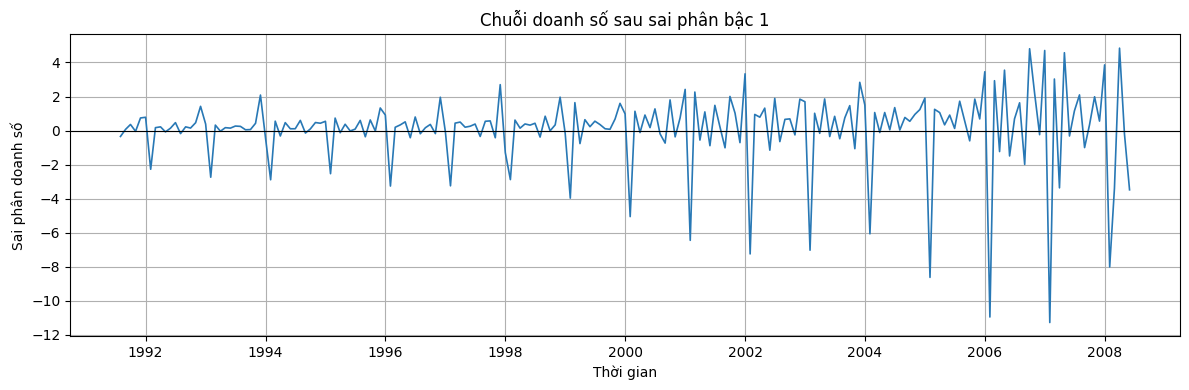

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(diff1, color="#2878B5", linewidth=1.2)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Chuỗi doanh số sau sai phân bậc 1")
plt.xlabel("Thời gian")
plt.ylabel("Sai phân doanh số")
plt.tight_layout()
plt.savefig("../reports/figures/04_differenced_series.png", dpi=250, bbox_inches="tight")
plt.show()

## 3. Biểu đồ ACF và PACF của sai phân bậc 1

- ACF cho biết tương quan giữa chuỗi và các giá trị trễ của chính nó.
- PACF cho biết tương quan ở một lag sau khi đã kiểm soát ảnh hưởng của các lag nằm giữa.
- Các cột vượt ngoài vùng tin cậy 95% là dấu hiệu tự tương quan đáng chú ý; việc chọn mô hình vẫn cần kiểm tra thêm bằng AIC/BIC và chẩn đoán phần dư ở Bài 5.

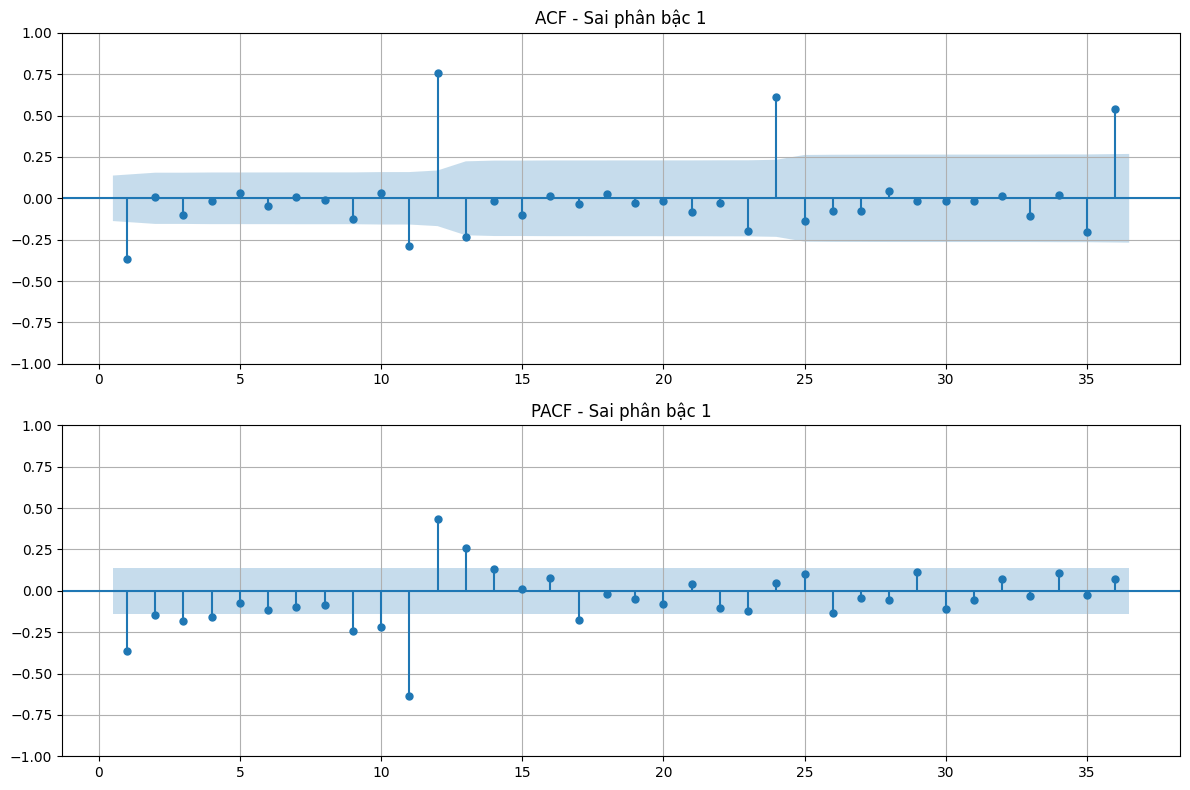

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(diff1, lags=36, zero=False, alpha=0.05, ax=axes[0])
axes[0].set_title("ACF - Sai phân bậc 1")
plot_pacf(diff1, lags=36, zero=False, alpha=0.05, method="ywm", ax=axes[1])
axes[1].set_title("PACF - Sai phân bậc 1")
plt.tight_layout()
plt.savefig("../reports/figures/04_acf_pacf_diff1.png", dpi=250, bbox_inches="tight")
plt.show()

## 4. Đọc dấu hiệu cutoff / tail-off

- **AR(p):** PACF thường cắt cụt quanh lag `p`, trong khi ACF suy giảm dần.
- **MA(q):** ACF thường cắt cụt quanh lag `q`, trong khi PACF suy giảm dần.
- **ARMA(p,q):** cả ACF và PACF thường suy giảm dần, không có điểm cắt cụt rõ ràng.
- Với dữ liệu này, cần chú ý lag 1 và đặc biệt lag 12, 24, 36. Các đỉnh ở bội số 12 gợi ý cấu trúc mùa vụ theo năm; đây không phải dấu hiệu chỉ của ARIMA không mùa vụ.

In [8]:
acf_values = acf(diff1, nlags=36, fft=False)
pacf_values = pacf(diff1, nlags=36, method="ywm")

print("Một số hệ số ACF đáng chú ý:")
for lag in [1, 2, 6, 12, 24, 36]:
    print(f"lag {lag:>2}: {acf_values[lag]: .3f}")

print("\nMột số hệ số PACF đáng chú ý:")
for lag in [1, 2, 6, 12, 24, 36]:
    print(f"lag {lag:>2}: {pacf_values[lag]: .3f}")

Một số hệ số ACF đáng chú ý:
lag  1: -0.365
lag  2:  0.006
lag  6: -0.049
lag 12:  0.757
lag 24:  0.615
lag 36:  0.539

Một số hệ số PACF đáng chú ý:
lag  1: -0.365
lag  2: -0.147
lag  6: -0.116
lag 12:  0.433
lag 24:  0.045
lag 36:  0.073
